# Actividad: Dataset - Notebook (baseline)

**Materia:** Operaciones de aprendizaje automático (TC5061, Gpo 10)
**Alumno:** Nicolás Hernández Ynurreta García, A01284528
**Fecha:** 3 de octubre de 2026

In [1]:
# librerias que se usan en el notebook
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## Paso 1: Carga y describe el dataset

Se usa el *AI4I 2020 Predictive Maintenance Dataset* del UCI Machine Learning Repository (Matzka, 2020), con licencia CC BY 4.0. Es un conjunto sintético que imita datos reales de mantenimiento predictivo de una máquina de fresado: cada registro es un ciclo de operación con sus condiciones de proceso y una etiqueta que indica si la máquina falló. Es un problema de clasificación binaria con objetivo `Machine failure`. Se eligió porque sus variables (temperaturas, velocidad, par y desgaste de herramienta) son las mismas que se vigilan en el mantenimiento de equipo industrial.

In [2]:
# lectura del csv desde la carpeta datos
df = pd.read_csv("datos/ai4i2020.csv")
print("Registros:", df.shape[0])
print("Columnas:", df.shape[1])
df.head()

Registros: 10000
Columnas: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# tipo de dato y valores no nulos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

El archivo tiene 10,000 registros y 14 columnas. Significado de cada una según la ficha del dataset, con el nombre que se usa en el resto del notebook:

| Columna original | Nombre en el notebook | Tipo | Significado |
|---|---|---|---|
| UDI | `udi` | entero | Identificador del registro (1 a 10,000) |
| Product ID | `id_producto` | texto | Letra de calidad del producto más un número de serie |
| Type | `tipo` | categórica | Calidad del producto: L baja, M media, H alta |
| Air temperature [K] | `temp_aire_K` | real | Temperatura del aire, alrededor de 300 K |
| Process temperature [K] | `temp_proceso_K` | real | Temperatura del proceso, cerca de la del aire más 10 K |
| Rotational speed [rpm] | `velocidad_rpm` | entero | Velocidad de giro de la herramienta |
| Torque [Nm] | `par_Nm` | real | Par en la herramienta, alrededor de 40 Nm |
| Tool wear [min] | `desgaste_min` | entero | Minutos de uso acumulados de la herramienta |
| Machine failure | `falla` | binaria | 1 si la máquina falló en el ciclo (variable objetivo) |
| TWF | `TWF` | binaria | Falla por desgaste de herramienta |
| HDF | `HDF` | binaria | Falla por disipación de calor |
| PWF | `PWF` | binaria | Falla de potencia |
| OSF | `OSF` | binaria | Falla por sobreesfuerzo |
| RNF | `RNF` | binaria | Falla aleatoria |

Las cinco últimas son los modos de falla: según la ficha, `Machine failure` vale 1 cuando ocurre al menos uno de ellos.

In [4]:
# nombres cortos en español, con la unidad al final
df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "id_producto",
    "Type": "tipo",
    "Air temperature [K]": "temp_aire_K",
    "Process temperature [K]": "temp_proceso_K",
    "Rotational speed [rpm]": "velocidad_rpm",
    "Torque [Nm]": "par_Nm",
    "Tool wear [min]": "desgaste_min",
    "Machine failure": "falla",
})
df.columns.tolist()

['udi',
 'id_producto',
 'tipo',
 'temp_aire_K',
 'temp_proceso_K',
 'velocidad_rpm',
 'par_Nm',
 'desgaste_min',
 'falla',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

## Paso 2: Realiza un análisis exploratorio (EDA)

Estadísticas descriptivas de las cinco variables de proceso:

In [5]:
# estadisticas descriptivas de las variables de proceso
numericas = ["temp_aire_K", "temp_proceso_K", "velocidad_rpm", "par_Nm", "desgaste_min"]
df[numericas].describe().round(2)

,temp_aire_K,temp_proceso_K,velocidad_rpm,par_Nm,desgaste_min
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


Las temperaturas tienen muy poca dispersión (desviación de 2.0 K en el aire y 1.48 K en el proceso). La velocidad tiene media de 1,538.78 rpm, pero su máximo, 2,886 rpm, está a más de 7 desviaciones estándar de la media, mientras que el mínimo está a solo 2; eso anticipa una cola larga a la derecha. El par va de 3.8 a 76.6 Nm alrededor de 40 Nm y el desgaste va de 0 a 253 min.

Tasa de falla: 3.39 %


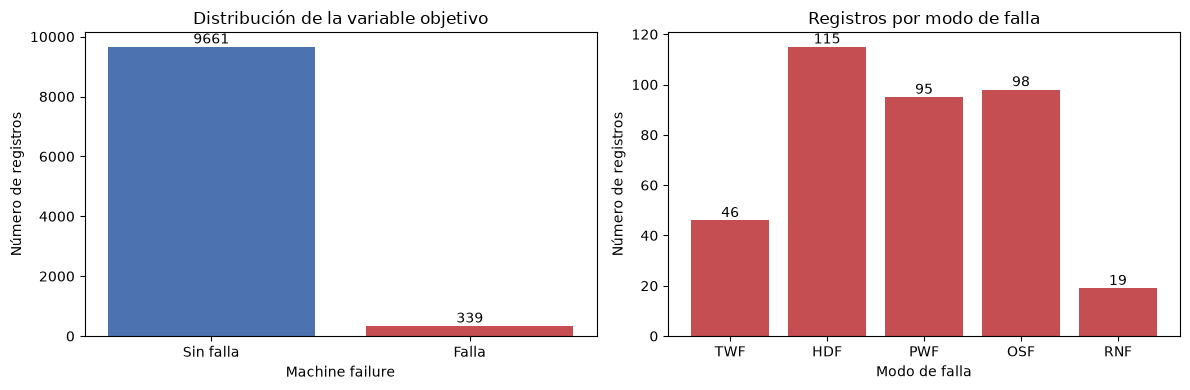

In [6]:
# balance de la variable objetivo y registros por modo de falla
modos = ["TWF", "HDF", "PWF", "OSF", "RNF"]
colores = {0: "#4C72B0", 1: "#C44E52"}
print("Tasa de falla:", round(df["falla"].mean() * 100, 2), "%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
conteo = df["falla"].value_counts().sort_index()
ax[0].bar(["Sin falla", "Falla"], conteo.values, color=[colores[0], colores[1]])
ax[0].bar_label(ax[0].containers[0])
ax[0].set_title("Distribución de la variable objetivo")
ax[0].set_xlabel("Machine failure")
ax[0].set_ylabel("Número de registros")
ax[1].bar(modos, df[modos].sum().values, color=colores[1])
ax[1].bar_label(ax[1].containers[0])
ax[1].set_title("Registros por modo de falla")
ax[1].set_xlabel("Modo de falla")
ax[1].set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

Solo 339 de 10,000 ciclos (3.39 %) terminan en falla, así que las clases están muy desbalanceadas. Un modelo que siempre diga "sin falla" acertaría 96.6 % de las veces sin aprender nada; por eso la exactitud sola no sirve para evaluar este problema. Las fallas más comunes son por disipación de calor (HDF), sobreesfuerzo (OSF) y potencia (PWF). La suma de los modos (373) no coincide con las 339 fallas, lo que se revisa en la limpieza.

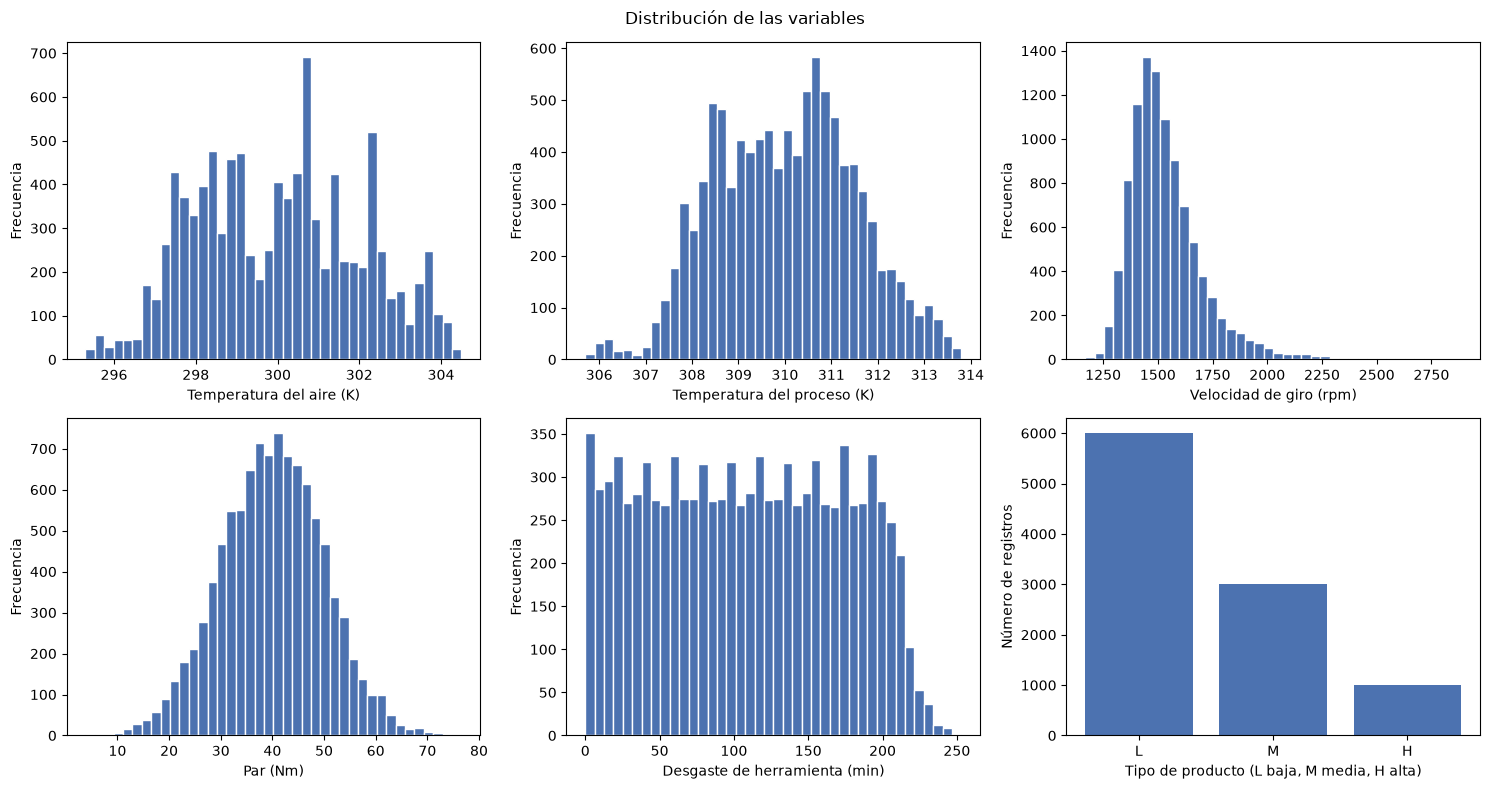

In [7]:
# histograma de cada variable de proceso y conteo por tipo de producto
etiquetas = {
    "temp_aire_K": "Temperatura del aire (K)",
    "temp_proceso_K": "Temperatura del proceso (K)",
    "velocidad_rpm": "Velocidad de giro (rpm)",
    "par_Nm": "Par (Nm)",
    "desgaste_min": "Desgaste de herramienta (min)",
}
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for eje, col in zip(ax.flat, numericas):
    eje.hist(df[col], bins=40, color=colores[0], edgecolor="white")
    eje.set_xlabel(etiquetas[col])
    eje.set_ylabel("Frecuencia")
tipos = df["tipo"].value_counts()
ax[1, 2].bar(tipos.index, tipos.values, color=colores[0])
ax[1, 2].set_xlabel("Tipo de producto (L baja, M media, H alta)")
ax[1, 2].set_ylabel("Número de registros")
fig.suptitle("Distribución de las variables")
plt.tight_layout()
plt.show()

Las dos temperaturas tienen una forma irregular, con varios picos, que viene del proceso de caminata aleatoria con el que se generaron. La velocidad está sesgada a la derecha, el par es casi simétrico y el desgaste se reparte de forma pareja entre 0 y unos 200 min, con pocos ciclos por encima. En el tipo de producto la proporción real es 60 % L, 30 % M y 10 % H, distinta del 50/30/20 que menciona la ficha del dataset; se trabaja con la proporción que traen los datos.

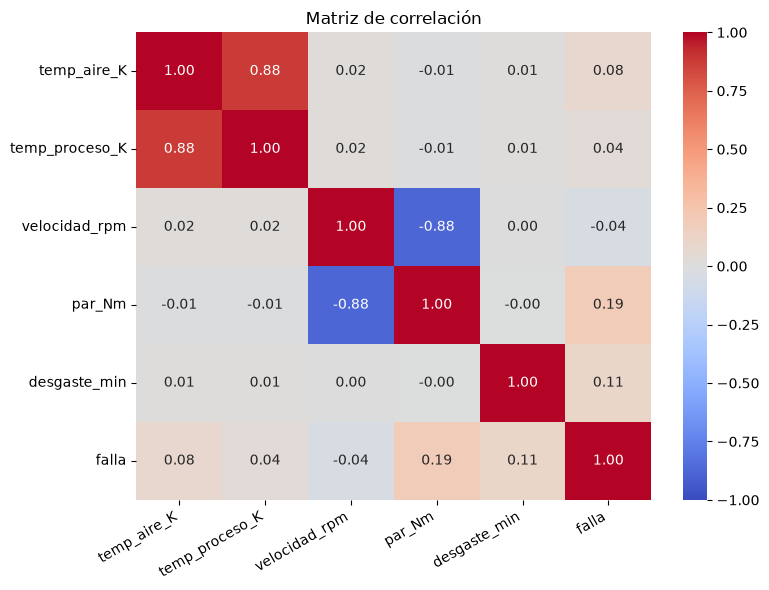

In [8]:
# correlacion entre las variables de proceso y la falla
plt.figure(figsize=(8, 6))
sns.heatmap(df[numericas + ["falla"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Hay dos pares de variables muy correlacionados: la temperatura del aire con la del proceso (0.88) y la velocidad con el par (-0.88). Lo segundo es físico, porque la máquina trabaja cerca de una potencia constante y a mayor velocidad corresponde menor par. Ninguna variable tiene correlación fuerte con la falla (la mayor es la del par, 0.19), lo que sugiere que la relación con la falla no es lineal.

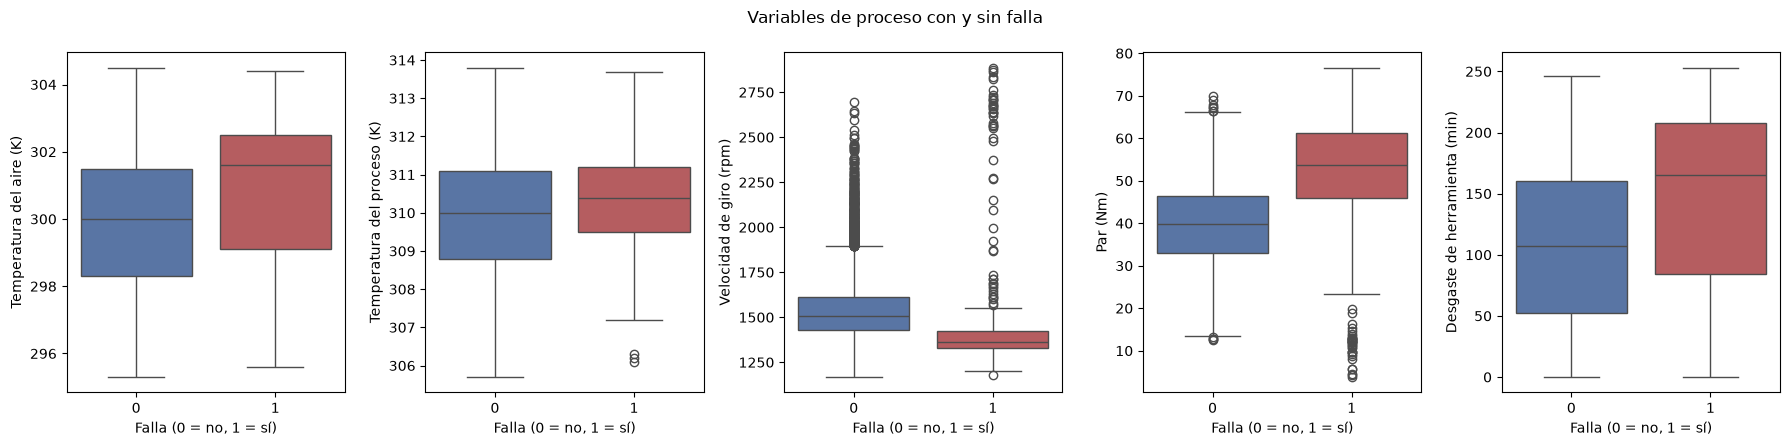

In [9]:
# cada variable comparada entre ciclos con y sin falla
fig, ax = plt.subplots(1, 5, figsize=(18, 4.5))
for eje, col in zip(ax, numericas):
    sns.boxplot(data=df, x="falla", y=col, hue="falla", palette=colores, legend=False, ax=eje)
    eje.set_xlabel("Falla (0 = no, 1 = sí)")
    eje.set_ylabel(etiquetas[col])
fig.suptitle("Variables de proceso con y sin falla")
plt.tight_layout()
plt.show()

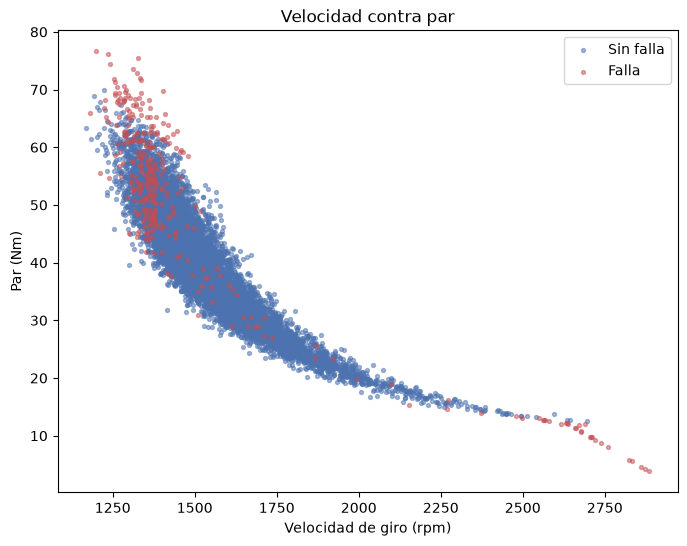

In [10]:
# velocidad contra par separando los ciclos con falla
plt.figure(figsize=(8, 6))
for valor, texto in [(0, "Sin falla"), (1, "Falla")]:
    parte = df[df["falla"] == valor]
    plt.scatter(parte["velocidad_rpm"], parte["par_Nm"], s=8, alpha=0.5, color=colores[valor], label=texto)
plt.title("Velocidad contra par")
plt.xlabel("Velocidad de giro (rpm)")
plt.ylabel("Par (Nm)")
plt.legend()
plt.show()

In [11]:
# porcentaje de ciclos con falla por tipo de producto
(df.groupby("tipo")["falla"].mean() * 100).round(2)

tipo
H    2.09
L    3.92
M    2.77
Name: falla, dtype: float64

Los ciclos con falla tienen par más alto, velocidad más baja, más desgaste y la temperatura del aire un poco mayor. En la gráfica de velocidad contra par las fallas se concentran en los extremos de la nube: par alto con velocidad baja (sobreesfuerzo y potencia excesiva) y par muy bajo con velocidad alta (potencia insuficiente). Son zonas que una frontera lineal no separa bien, algo a considerar para el modelo base. Por tipo, los productos L fallan más (3.92 %) que los M (2.77 %) y los H (2.09 %).

## Paso 3: Limpia los datos

Se revisan valores faltantes, duplicados, consistencia de la etiqueta, valores imposibles, outliers y tipos. Cada decision se anota después de la celda que la revisa.

In [12]:
# valores faltantes por columna
df.isna().sum()

udi               0
id_producto       0
tipo              0
temp_aire_K       0
temp_proceso_K    0
velocidad_rpm     0
par_Nm            0
desgaste_min      0
falla             0
TWF               0
HDF               0
PWF               0
OSF               0
RNF               0
dtype: int64

**Faltantes.** Ninguna columna tiene valores nulos, así que no hace falta imputar. Si en datos nuevos llegaran faltantes, lo correcto sería agregar un imputador dentro del pipeline del modelo para que se ajuste solo con los datos de entrenamiento.

In [13]:
# filas repetidas, con y sin los identificadores
print("Filas duplicadas:", df.duplicated().sum())
print("Duplicadas sin udi ni id_producto:", df.drop(columns=["udi", "id_producto"]).duplicated().sum())
print("id_producto repetidos:", df["id_producto"].duplicated().sum())

Filas duplicadas: 0
Duplicadas sin udi ni id_producto: 0
id_producto repetidos: 0


**Duplicados.** No hay filas repetidas, ni siquiera ignorando los identificadores, y cada `id_producto` aparece una sola vez. No se elimina nada.

In [14]:
# la falla debería coincidir con tener al menos un modo de falla
con_modo = df[modos].sum(axis=1) > 0
pd.crosstab(df["falla"], con_modo, rownames=["falla"], colnames=["tiene algún modo"])

tiene algún modo,False,True
falla,,
0,9643,18
1,9,330


**Consistencia de la etiqueta.** Según la ficha, `falla` vale 1 cuando ocurre al menos uno de los cinco modos. Hay 9 registros marcados como falla sin ningún modo y 18 con algún modo (todos de falla aleatoria, RNF) pero con `falla` en 0. Esas etiquetas contradicen la definición y no hay forma de saber cuál de las dos columnas está mal, así que se eliminan los 27 registros (0.27 % de los datos). Quitarlos casi no cambia el tamaño de la muestra y evita entrenar y evaluar con ejemplos contradictorios.

In [15]:
# se quitan los registros con etiqueta contradictoria
inconsistentes = (df["falla"] == 1) != con_modo
df_limpio = df[~inconsistentes].copy()
print("Registros eliminados:", inconsistentes.sum())
print("Registros restantes:", len(df_limpio))

Registros eliminados: 27
Registros restantes: 9973


In [16]:
# revisión de rangos físicos
temperaturas = df_limpio[["temp_aire_K", "temp_proceso_K"]]
print("Temperaturas fuera de 250 a 350 K:", ((temperaturas < 250) | (temperaturas > 350)).sum().sum())
print("Velocidad o par en cero o negativos:", (df_limpio[["velocidad_rpm", "par_Nm"]] <= 0).sum().sum())
print("Desgaste negativo:", (df_limpio["desgaste_min"] < 0).sum())
print("Proceso más frío que el aire:", (df_limpio["temp_proceso_K"] < df_limpio["temp_aire_K"]).sum())

Temperaturas fuera de 250 a 350 K: 0
Velocidad o par en cero o negativos: 0
Desgaste negativo: 0
Proceso más frío que el aire: 0


**Valores imposibles.** Todas las temperaturas están en un rango físico razonable, no hay velocidades ni pares en cero o negativos, no hay desgaste negativo y la temperatura del proceso nunca es menor que la del aire. No se corrige nada.

In [17]:
# outliers con la regla de 1.5 veces el rango intercuartil
q1 = df_limpio[numericas].quantile(0.25)
q3 = df_limpio[numericas].quantile(0.75)
iqr = q3 - q1
fuera = (df_limpio[numericas] < q1 - 1.5 * iqr) | (df_limpio[numericas] > q3 + 1.5 * iqr)
con_outlier = fuera.any(axis=1)
print("Tasa de falla general:", round(df_limpio["falla"].mean() * 100, 2), "%")
print("Fallas en registros con algún outlier:", df_limpio.loc[con_outlier, "falla"].sum(), "de", df_limpio["falla"].sum())
print("Fallas de potencia (PWF) en registros con algún outlier:", df_limpio.loc[con_outlier, "PWF"].sum(), "de", df_limpio["PWF"].sum())
pd.DataFrame({
    "outliers": fuera.sum(),
    "tasa de falla en outliers (%)": [df_limpio.loc[fuera[col], "falla"].mean() * 100 for col in numericas],
}).round(2)

Tasa de falla general: 3.31 %
Fallas en registros con algún outlier: 72 de 330
Fallas de potencia (PWF) en registros con algún outlier: 65 de 95


,outliers,tasa de falla en outliers (%)
temp_aire_K,0,NaN
temp_proceso_K,0,NaN
velocidad_rpm,418,8.37
par_Nm,70,88.57
desgaste_min,0,NaN


**Outliers.** Con la regla de 1.5 veces el rango intercuartil solo aparecen outliers en la velocidad (418) y en el par (70); en las demás variables no hay, por eso su tasa aparece como NaN. No se eliminan ni se recortan: son valores físicamente posibles y concentran justo los casos que interesan, porque 8.37 % de los outliers de velocidad y 88.57 % de los de par terminan en falla, contra 3.31 % en general. Quitarlos borraría 72 de las 330 fallas, entre ellas 65 de las 95 fallas de potencia (PWF). La diferencia de escalas entre variables se resuelve con el escalado dentro del pipeline del modelo.

In [18]:
# tipos: tipo como categoría y medidas como float; fuera identificadores y modos de falla
df_limpio["tipo"] = df_limpio["tipo"].astype("category")
df_limpio[numericas] = df_limpio[numericas].astype(float)
df_limpio.drop(columns=["udi", "id_producto"] + modos, inplace=True)
print("Forma final:", df_limpio.shape)
df_limpio.dtypes

Forma final: (9973, 7)


tipo              category
temp_aire_K        float64
temp_proceso_K     float64
velocidad_rpm      float64
par_Nm             float64
desgaste_min       float64
falla                int64
dtype: object

**Tipos y columnas.** `tipo` pasa a categoría y las medidas a `float`: la velocidad y el desgaste venían como enteros, pero son medidas continuas. Se quitan `udi` e `id_producto` porque son identificadores sin información del proceso (la letra del `id_producto` ya está en `tipo`). También se quitan los cinco modos de falla: describen la falla una vez que ocurrió, así que dejarlos sería una fuga de información y el modelo vería la respuesta. El conjunto limpio queda con 9,973 registros, seis variables de entrada y el objetivo.

## Paso 4: Entrena un modelo base

Se separan las variables de entrada del objetivo y se dividen en 80 % entrenamiento y 20 % prueba. La división se estratifica por `falla` para que las dos partes conserven la misma proporción de fallas; con poco más de 3 % de casos positivos, una división al azar podría dejar la prueba con muy pocas fallas y las métricas serían poco confiables (Géron, 2019, cap. 2). La semilla es 42 para que la división se pueda repetir.

In [19]:
# entradas, objetivo y division estratificada 80/20
X = df_limpio.drop(columns="falla")
y = df_limpio["falla"]
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entrenamiento:", X_entrenamiento.shape)
print("Prueba:", X_prueba.shape)
print("Tasa de falla en entrenamiento:", round(y_entrenamiento.mean() * 100, 2), "%")
print("Tasa de falla en prueba:", round(y_prueba.mean() * 100, 2), "%")

Entrenamiento: (7978, 6)
Prueba: (1995, 6)
Tasa de falla en entrenamiento: 3.31 %
Tasa de falla en prueba: 3.31 %


Como vara mínima se entrena un `DummyClassifier` que siempre predice la clase más frecuente, es decir, "sin falla". No aprende nada de las variables; un modelo que no lo supere no aporta.

In [20]:
# modelo tonto: siempre predice la clase mayoritaria
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_entrenamiento, y_entrenamiento)
print("Clase que predice siempre:", dummy.predict(X_prueba.head(1))[0])

Clase que predice siempre: 0


Como modelo base real se usa una regresión logística, el clasificador lineal más sencillo para un objetivo binario. Va dentro de un `Pipeline` junto con el preprocesamiento: `StandardScaler` para las cinco variables numéricas y `OneHotEncoder` para `tipo`. Así el escalado se ajusta solo con los datos de entrenamiento y se aplica igual a los de prueba, sin fuga de información (Géron, 2019, cap. 2). Se usa `class_weight="balanced"` porque con 3.3 % de fallas el modelo, sin pesos, reduce su error diciendo casi siempre "sin falla"; con pesos balanceados cada falla cuenta más en el entrenamiento. Los demás hiperparámetros quedan por defecto (`C = 1.0`) y `max_iter=1000` asegura que converja.

In [21]:
# pipeline: escalado de numéricas y one hot de tipo antes de la regresión logística
preprocesamiento = ColumnTransformer([
    ("numericas", StandardScaler(), numericas),
    ("tipo", OneHotEncoder(handle_unknown="ignore"), ["tipo"]),
])
modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
modelo.fit(X_entrenamiento, y_entrenamiento)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['tipo','temp_aire_K','temp_proceso_K','velocidad_rpm','par_Nm', 'desgaste_min']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('tipo', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remain

## Paso 5: Evalúa el modelo

Se calculan exactitud, precisión, recall y F1 sobre el conjunto de prueba para los dos modelos, con la falla como clase positiva. La precisión dice qué parte de las alarmas fueron fallas reales y el recall qué parte de las fallas reales se detectaron; F1 es la media armónica de las dos.

In [22]:
# metricas en prueba de los dos modelos
def metricas(y_real, y_pred):
    return {
        "exactitud": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred),
        "f1": f1_score(y_real, y_pred, zero_division=0),
    }

pred_dummy = dummy.predict(X_prueba)
pred_modelo = modelo.predict(X_prueba)
resultados = pd.DataFrame([metricas(y_prueba, pred_dummy), metricas(y_prueba, pred_modelo)], index=["dummy", "regresion_logistica"]).round(4)
resultados

,exactitud,precision,recall,f1
dummy,0.9669,0.000,0.0000,0.0000
regresion_logistica,0.8140,0.136,0.8636,0.2351


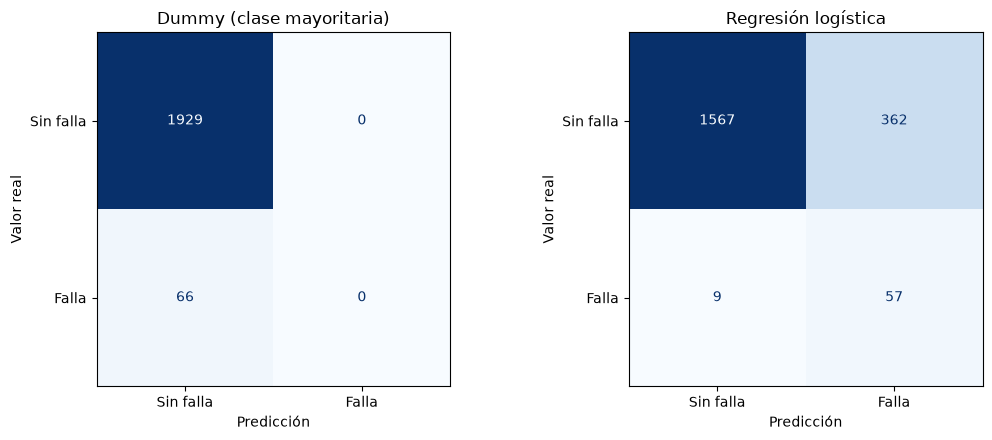

In [23]:
# matrices de confusión lado a lado, se guardan para mlflow
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, (titulo, pred) in zip(ax, [("Dummy (clase mayoritaria)", pred_dummy), ("Regresión logística", pred_modelo)]):
    ConfusionMatrixDisplay(confusion_matrix(y_prueba, pred), display_labels=["Sin falla", "Falla"]).plot(ax=eje, cmap="Blues", colorbar=False, values_format="d")
    eje.set_title(titulo)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Valor real")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=120)
plt.show()

**Interpretación.** El dummy tiene la mayor exactitud (96.69 %) y aun así no sirve: nunca predice una falla, así que su precisión, recall y F1 valen 0 y deja pasar las 66 fallas del conjunto de prueba. Es la muestra de que en un problema desbalanceado la exactitud engaña.

La regresión logística baja la exactitud a 81.40 %, pero detecta 57 de las 66 fallas (recall de 0.8636) y solo deja pasar 9. El costo está en la precisión: de 419 alarmas, 362 son falsas, así que solo 13.6 % de las alarmas corresponden a una falla real, y el F1 queda en 0.2351.

En mantenimiento los dos errores no cuestan lo mismo. Un falso negativo es una falla que nadie anticipó: paro no programado, herramienta rota, pieza perdida y, en equipo pesado, un riesgo para el personal. Un falso positivo es una inspección que no hacía falta, que cuesta tiempo de un técnico y unos minutos de paro. Por eso se prioriza el recall, y en ese sentido la regresión logística sí supera al dummy y es un baseline útil. Aun así, 362 falsas alarmas en 1,995 ciclos (18 %) serían demasiadas en planta: con tantas alertas el personal terminaría por ignorarlas.

La precisión baja es coherente con el EDA: las fallas ocurren en zonas específicas de la curva velocidad-par y con desgaste alto, que una frontera lineal no aísla. Esta queda como la vara para los siguientes modelos: deberán conservar un recall cercano a 0.86 y subir la precisión y el F1, por ejemplo con variables derivadas como la potencia (par por velocidad) y la diferencia de temperaturas, con modelos no lineales como los árboles de decisión o ajustando el umbral de decisión.

## Paso 6: Registra el experimento en MLFlow

El servidor de MLflow corre en local con `mlflow server --host 127.0.0.1 --port 5000` y el notebook se conecta a él con `set_tracking_uri`. Se crea el experimento `baseline_mantenimiento_ai4i` y se registra un run por modelo para poder compararlos en la interfaz. En cada run se guardan los parámetros de la división y del modelo con `log_params`, las cuatro metricas de prueba con `log_metrics`, la figura de las matrices de confusión con `log_artifact` y el modelo entrenado con `mlflow.sklearn.log_model`, siguiendo la documentación de MLflow Tracking (MLflow, s.f.).

In [24]:
# conexion al servidor local y experimento
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("baseline_mantenimiento_ai4i")

# parámetros de la división, comunes a los dos runs, y los de cada modelo
division = {"test_size": 0.2, "random_state": 42, "estratificado": True, "registros_entrenamiento": len(X_entrenamiento), "registros_prueba": len(X_prueba)}
parametros = {
    "dummy": {"modelo": "DummyClassifier", "strategy": "most_frequent"},
    "regresion_logistica": {"modelo": "LogisticRegression", "escalado": "StandardScaler", "class_weight": "balanced", "C": 1.0, "max_iter": 1000},
}
firma = infer_signature(X_prueba, pred_modelo)

for nombre, estimador in [("dummy", dummy), ("regresion_logistica", modelo)]:
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params({**division, **parametros[nombre]})
        mlflow.log_metrics(resultados.loc[nombre].to_dict())
        mlflow.log_artifact("matriz_confusion.png")
        mlflow.sklearn.log_model(estimador, name="modelo", signature=firma, input_example=X_prueba.head())

🏃 View run dummy at: http://127.0.0.1:5000/#/experiments/1/runs/19a12b56709c4608ac6b4734186574db
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run regresion_logistica at: http://127.0.0.1:5000/#/experiments/1/runs/7da1e10c5d1d4a0ba788ce88a94e02ab
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [25]:
# runs que quedaron registrados en el experimento
runs = mlflow.search_runs(experiment_names=["baseline_mantenimiento_ai4i"], max_results=2)
runs[["tags.mlflow.runName", "params.modelo", "metrics.exactitud", "metrics.precision", "metrics.recall", "metrics.f1"]]

,tags.mlflow.runName,params.modelo,metrics.exactitud,metrics.precision,metrics.recall,metrics.f1
0,regresion_logistica,LogisticRegression,0.8140,0.136,0.8636,0.2351
1,dummy,DummyClassifier,0.9669,0.000,0.0000,0.0000


Capturas de la interfaz de MLflow: la lista de runs del experimento `baseline_mantenimiento_ai4i` con sus métricas y el detalle del run `regresion_logistica` con sus métricas y sus diez parámetros:

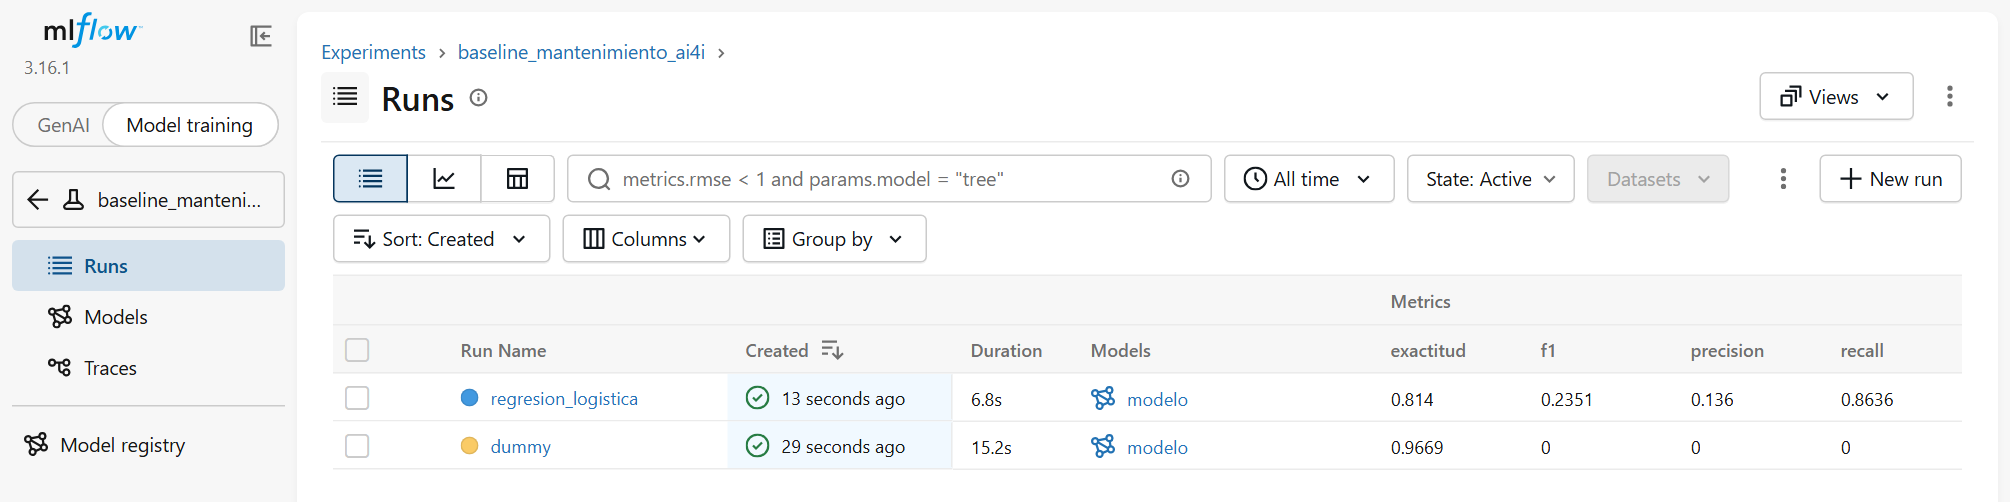

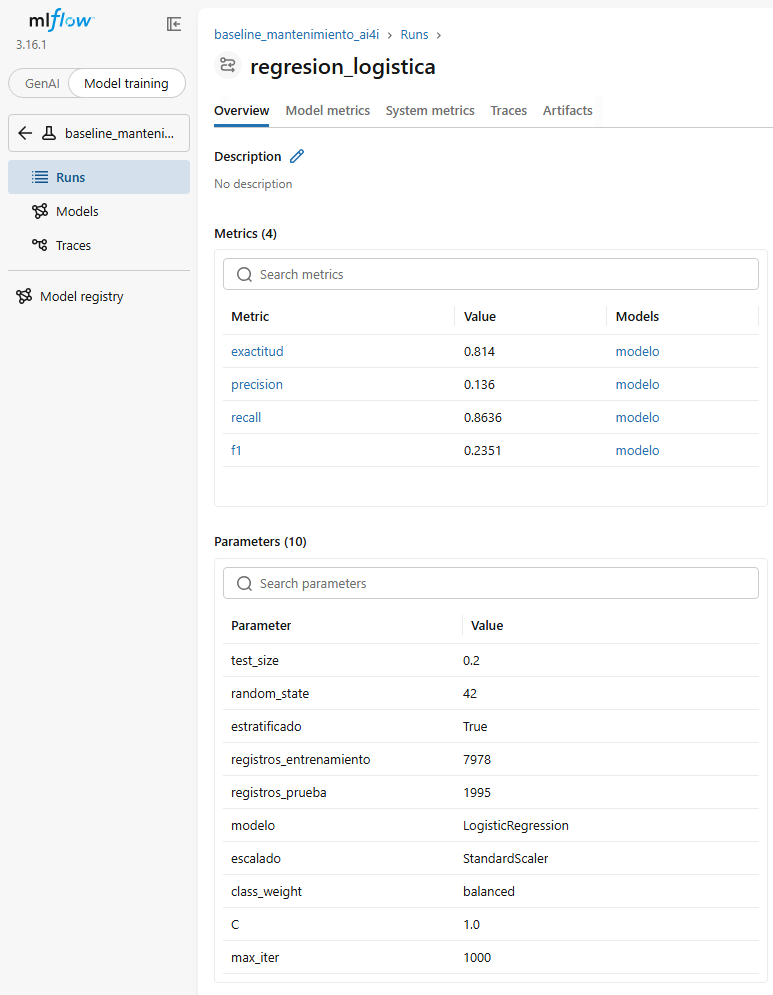

In [26]:
# capturas de la interfaz de mlflow: lista de runs y detalle del run de regresión logística
display(Image("mlflow_ui.png"), Image("mlflow_run.png"))

## Paso 7: Redacta una reflexión

Este flujo funciona, pero depende de que yo lo corra a mano y en orden. Lo primero que mejoraría con MLOps es la reproducibilidad: versionar el código con Git y también el CSV, para que cada run de MLflow apunte a una versión exacta de los datos. Después convertiría las revisiones de limpieza que hice con prints (faltantes, duplicados, etiquetas contradictorias, rangos físicos) en pruebas automáticas con PyTest que corran antes de entrenar; hoy un archivo con errores pasaría sin que nadie lo notara. También pasaría el notebook a un pipeline de scripts y usaría el registro de modelos de MLflow para promover un modelo solo si supera al baseline en recall y F1, no en exactitud, que aqui resultó engañosa. Por último, ya en operación el modelo necesita vigilancia, porque las condiciones cambian y el desempeño se degrada sin avisar (Treveil et al., 2020); lo serviría con FastAPI y monitorearía la deriva de los datos con Evidently.

En mi trabajo, en una empresa de grúas y servicios industriales, esto aplica casi directo. Los equipos generan datos de horas de operación, cargas y temperaturas, y aparece el mismo dilema: una falla no detectada en una grúa no es solo un paro, es un riesgo de seguridad, mientras que una inspección de más cuesta poco. Por eso la métrica se elige según el costo del error, y por eso importa la trazabilidad: ante una auditoría o un incidente hay que poder explicar qué modelo recomendó qué, con qué datos y con qué versión.

## Referencias

- Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2.ª ed.). O'Reilly Media.
- Matzka, S. (2020). *AI4I 2020 predictive maintenance dataset* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C
- MLflow. (s.f.). *MLflow Tracking APIs* [Documentación]. https://mlflow.org/docs/latest/ml/tracking/tracking-api/
- Treveil, M., Omont, N., Stenac, C., Lefevre, K., Phan, D., Zentici, J., Lavoillotte, A., Miyazaki, M., & Heidmann, L. (2020). *Introducing MLOps: How to scale machine learning in the enterprise*. O'Reilly Media.